# Zeros shot mutation effect prediction with protein langauge models




## Masked Marginal Scoring Function

The masked marginal scoring function is used to predict the effects of mutations on protein function based on changes in the probabilistic model's output. This function computes the difference in log probabilities for the mutated (mt) and wild-type (wt) residues at specific positions in the protein sequence.

### Formula
The scoring function is defined as:

$$
\sum_{i \in M} \left( \log p(x_i = x_i^{mt} \mid x_{-M}) - \log p(x_i = x_i^{wt} \mid x_{-M}) \right)
$$

Where:
- $M$ represents the set of masked residues where mutations occur.
- $x_i^{mt}$ is the mutant-type residue at position $i$.
- $x_i^{wt}$ is the wild-type residue at position $i$.
- $x_{-M}$ denotes the sequence context excluding the masked residues.

### Interpretation
The function quantifies the difference in the model's confidence (in log space) between the mutated sequence and the wild-type sequence. A more negative score suggests that the mutation is deleterious, affecting the protein function adversely, whereas a less negative or positive score may indicate a neutral or potentially beneficial effect of the mutation.

## Setting Up Protein Sequence Analysis with ESM Model

This notebook sets up the necessary tools and models for analyzing protein sequences using the ESM (Evolutionary Scale Modeling) models from Facebook AI Research. The focus here is on loading a specific ESM model and preparing it for sequence analysis tasks.

### Libraries and Extensions
We start by importing necessary libraries:
- `torch`: For tensor computations and neural network operations.
- `esm`: For loading and utilizing pretrained ESM models specifically designed for protein sequences.
- `transformers`: For easy access to pre-trained models and utilities for NLP tasks.
- `matplotlib.pyplot`: For plotting graphs.
- `numpy`: For numerical operations.
- `ipywidgets`: For interactive widgets in the Jupyter environment.
- `IPython.display`: For displaying objects in the Jupyter notebooks.

Additionally, we configure the notebook to reload modules before executing the code (useful during development) and set interactive output for all computation cells.

### Data Preparation
We define a list of amino acids and a sample protein sequence. The protein sequence provided is an example sequence which will be used for demonstration purposes:



### Model Setup
We load the tokenizer and model from the Hugging Face model repository:
- `model_name`: Identifier for the pre-trained ESM model.

Using the tokenizer, we can convert amino acid sequences into a format suitable for the model. The model, once loaded, is ready to make predictions or analyze the sequences.



In [ ]:
!pip install torch esm numpy matplotlib umap-learn seaborn datasets


     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.4/44.4 kB 2.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.5/2.5 MB 42.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 56.3/56.3 MB 12.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.7/9.7 MB 50.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.3/3.3 MB 56.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 139.3/139.3 kB 4.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.0/2.0 MB 50.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 302.7/302.7 kB 14.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.2/2.2 MB 29.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 14.0/14.0 MB 55.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.6/1.6 MB 37.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 85.7/85.7 kB 9.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.1/3.1 MB 41.7 M

In [ ]:
import torch
import esm
from transformers import AutoTokenizer, EsmForMaskedLM
from torch.utils.data import Dataset
from torch.utils.data import DataLoader
import matplotlib.pyplot as plt
import numpy as np
import ipywidgets as widgets
from IPython.display import display

from IPython.core.interactiveshell import InteractiveShell
#InteractiveShell.ast_node_interactivity = "all"


# Listing amino acids
amino_acids = list("ACDEFGHIKLMNPQRSTVWY")
len(amino_acids)

protein_sequence = "MAPLRKTYVLKLYVAGNTPNSVRALKTLNNILEKEFKGVYALKVIDVLKNPQLAEEDKILATPTLAKVLPPPVRRIIGDLSNREKVLIGLDLLYEEIGDQAEDDLGLE"
model_name = "facebook/esm2_t6_8M_UR50D"

tokenizer = AutoTokenizer.from_pretrained(model_name)
model = EsmForMaskedLM.from_pretrained(model_name)



/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


tokenizer_config.json:   0%|          | 0.00/95.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/93.0 [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/125 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/775 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/31.4M [00:00<?, ?B/s]

In [ ]:
# Lets take a closer look:
model


EsmForMaskedLM(
  (esm): EsmModel(
    (embeddings): EsmEmbeddings(
      (word_embeddings): Embedding(33, 320, padding_idx=1)
      (dropout): Dropout(p=0.0, inplace=False)
      (position_embeddings): Embedding(1026, 320, padding_idx=1)
    )
    (encoder): EsmEncoder(
      (layer): ModuleList(
        (0-5): 6 x EsmLayer(
          (attention): EsmAttention(
            (self): EsmSelfAttention(
              (query): Linear(in_features=320, out_features=320, bias=True)
              (key): Linear(in_features=320, out_features=320, bias=True)
              (value): Linear(in_features=320, out_features=320, bias=True)
              (dropout): Dropout(p=0.0, inplace=False)
              (rotary_embeddings): RotaryEmbedding()
            )
            (output): EsmSelfOutput(
              (dense): Linear(in_features=320, out_features=320, bias=True)
              (dropout): Dropout(p=0.0, inplace=False)
            )
            (LayerNorm): LayerNorm((320,), eps=1e-05, elementwise_a

## Examining Tokenized Protein Sequences

After tokenizing the protein sequence using the pretrained model's tokenizer, it is useful to understand how the tokenized sequence is structured, including the incorporation of special tokens.

### Tokenization Process

The protein sequence is converted into a format that the model can process using the following line of code:

```python
input_ids = tokenizer.encode(protein_sequence, return_tensors="pt")
```


In [ ]:
input_ids = tokenizer.encode(protein_sequence, return_tensors="pt")
sequence_length = input_ids.shape[1] - 2
end_pos = sequence_length



In [ ]:
### How the tokenized proteins sequence looks like?


In [ ]:
input_ids.shape
input_ids


tensor([[ 0, 20,  5, 14,  4, 10, 15, 11, 19,  7,  4, 15,  4, 19,  7,  5,  6, 17,
         11, 14, 17,  8,  7, 10,  5,  4, 15, 11,  4, 17, 17, 12,  4,  9, 15,  9,
         18, 15,  6,  7, 19,  5,  4, 15,  7, 12, 13,  7,  4, 15, 17, 14, 16,  4,
          5,  9,  9, 13, 15, 12,  4,  5, 11, 14, 11,  4,  5, 15,  7,  4, 14, 14,
         14,  7, 10, 10, 12, 12,  6, 13,  4,  8, 17, 10,  9, 15,  7,  4, 12,  6,
          4, 13,  4,  4, 19,  9,  9, 12,  6, 13, 16,  5,  9, 13, 13,  4,  6,  4,
          9,  2]])

## Understanding Special and Amino Acid Tokens

### Special Tokens and Their IDs

The code retrieves all extended special tokens defined in the tokenizer and prints each token alongside its corresponding ID. These special tokens typically include symbols like start and end of sequence markers, which are essential for the model to understand the boundaries of input sequences.

Understanding how different control tokens are represented numerically is crucial for custom operations like modifying sequences or implementing new model behaviors.

### Amino Acid Tokens and Their IDs

The code also iterates over a list of amino acids, printing each amino acid along with its token ID. This step is crucial for understanding how the tokenizer converts biological sequences into data that the model can process, ensuring that each amino acid is correctly encoded. This information aids in troubleshooting issues related to sequence processing and enhances the interpretability of model predictions.


In [ ]:
special_tokens = tokenizer.all_special_tokens_extended

for special_token in special_tokens:
    print(f'{special_token}    ID: {tokenizer.convert_tokens_to_ids(special_token)}' )

for token in amino_acids:
    print(f'{token}    ID: {tokenizer.convert_tokens_to_ids(token)}' )



<eos>    ID: 2
<unk>    ID: 3
<pad>    ID: 1
<cls>    ID: 0
<mask>    ID: 32
A    ID: 5
C    ID: 23
D    ID: 13
E    ID: 9
F    ID: 18
G    ID: 6
H    ID: 21
I    ID: 12
K    ID: 15
L    ID: 4
M    ID: 20
N    ID: 17
P    ID: 14
Q    ID: 16
R    ID: 10
S    ID: 8
T    ID: 11
V    ID: 7
W    ID: 22
Y    ID: 19


## Creating Mapping and Lookup Tables for Amino Acids

### Mapping Amino Acids to Token IDs

The code segment creates a dictionary mapping each amino acid to its corresponding token ID (`aa2esmid`). This mapping is crucial for translating amino acid sequences into the format required by the model for processing.

### Reverse Mapping from Token IDs to Amino Acids

Simultaneously, a reverse mapping (`esmid2aa`) is established that allows us to convert back from token IDs to amino acids. This is useful for interpreting the model's outputs, where we might receive token IDs that need to be converted back to their respective amino acid representations.

### Amino Acid Index for Heatmap

Finally, the code sets up a lookup table (`aa2heatmap_idx`) that assigns each amino acid a unique index. This index will be used later to create a heatmap visualization of the model's predictions or activations.


In [ ]:
aa2esmid = {}
esmid2aa = {}
aa2heatmap_idx = {}
for i, amino_acid in enumerate(amino_acids):
    esm_id = tokenizer.convert_tokens_to_ids(amino_acid)
    aa2esmid[amino_acid] = esm_id
    esmid2aa[esm_id] = amino_acid
    aa2heatmap_idx[amino_acid] = i


## Creating a Masking Dataset for Protein Sequence Analysis

### Overview
To evaluate the effects of mutations on protein function, we employ a scoring function that compares the log probabilities of mutant-type and wild-type residues at specific positions. This approach is based on systematically masking each position in the protein sequence, then analyzing the impact of these changes using a machine learning model.

### Formula for Scoring
The scoring function is defined as:

$$
\sum_{i \in M} \left( \log p(x_i = x_i^{mt} \mid x_{-M}) - \log p(x_i = x_i^{wt} \mid x_{-M}) \right)
$$

Where:
- $M$ represents the set of masked residues where mutations occur.
- $x_i^{mt}$ is the mutant-type residue at position $i$.
- $x_i^{wt}$ is the wild-type residue at position $i$.
- $x_{-M}$ denotes the sequence context excluding the masked residues.

### Masking Process
The process of creating a dataset for this analysis involves the following steps:
1. **Iteration through the Sequence:** We begin at position 1 (corresponding to the first amino acid) and iterate through the entire protein sequence.
2. **Masking:** At each position, the wild-type amino acid (WT AA) is replaced with a special mask token. The token ID for this mask token is 32.
3. **Collection of Modified Sequences:** Each modified sequence, now containing one masked position, is collected into a list.
4. **Conversion to Tensor:** Finally, the list of modified sequences is converted into a single tensor array for batch processing by the model.

By the end of this procedure, we will have generated 108 new token sequences (assuming the original sequence has 108 positions), each sequence with a different position masked. This setup allows for a systematic evaluation of each position's influence on the protein's function.


In [ ]:
input_ids_list = []
start_pos=1

for position in range(start_pos, end_pos + 1):
    # Mask the target position
    masked_input_ids = input_ids.clone()
    masked_input_ids[0, position] = tokenizer.mask_token_id

    #with torch.no_grad():
    #    logits = model(masked_input_ids).logits
    input_ids_list.append(masked_input_ids[0])

# Stacking the updated sequences
batched_input_ids = torch.stack(input_ids_list)
input_ids_list[0:2]
batched_input_ids.shape

torch.Size([108, 110])

## Defining the ProteinDataset Class

### Purpose of the Dataset Class
The `ProteinDataset` class is designed to handle and store the array. It encapsulates the data within a custom dataset structure that is compatible with PyTorch's data handling utilities. This setup is essential for batch processing and streamlined data manipulation during the training and evaluation phases of machine learning models.

### Structure and Functionality
- **Initialization (`__init__`):** The constructor takes a tensor containing all the input ID batches derived from the protein sequences. This tensor is stored as an attribute for easy access across the dataset class.
- **Length (`__len__`):** This method returns the total number of entries in the dataset, allowing PyTorch utilities to understand the dataset size for operations like batching and iterating over data.
- **Item Access (`__getitem__`):** By defining this method, the dataset allows for indexed access to its contents, making it compatible with PyTorch's DataLoader class for efficient retrieval and processing of data in a model-friendly format.



In [ ]:
class ProteinDataset(Dataset):
    def __init__(self, data):
        """
        Args:
            data (Tensor): A tensor containing all the input_ids batches.
        """
        self.data = data

    def __len__(self):
        return self.data.size(0)

    def __getitem__(self, idx):
        return self.data[idx]

## Setting Up the DataLoader

### Configuration
We define a `DataLoader` for the `ProteinDataset` with a `batch_size` of 2. This small batch size is specifically chosen for testing purposes, allowing for quick and manageable computations that are easier to debug and verify.

### Purpose
The `DataLoader` facilitates efficient, batch-wise iteration over the dataset during model training or evaluation. It automates the process of sampling, batching, and shuffling the data (if required), providing a seamless integration with PyTorch's training loops.


In [ ]:
batched_input_ids.shape

torch.Size([108, 110])

In [ ]:
protein_ds = ProteinDataset(batched_input_ids[0:3,:])

batch_size = 2 # It is very small, just for testing purposes
dataloader = DataLoader(protein_ds, batch_size=batch_size)
print(protein_ds[0])
print(len(protein_ds))



tensor([ 0, 32,  5, 14,  4, 10, 15, 11, 19,  7,  4, 15,  4, 19,  7,  5,  6, 17,
        11, 14, 17,  8,  7, 10,  5,  4, 15, 11,  4, 17, 17, 12,  4,  9, 15,  9,
        18, 15,  6,  7, 19,  5,  4, 15,  7, 12, 13,  7,  4, 15, 17, 14, 16,  4,
         5,  9,  9, 13, 15, 12,  4,  5, 11, 14, 11,  4,  5, 15,  7,  4, 14, 14,
        14,  7, 10, 10, 12, 12,  6, 13,  4,  8, 17, 10,  9, 15,  7,  4, 12,  6,
         4, 13,  4,  4, 19,  9,  9, 12,  6, 13, 16,  5,  9, 13, 13,  4,  6,  4,
         9,  2])
3


## Model Execution and Data Handling

### Device Setup
The code checks if a CUDA-capable GPU is available. If available, it sets up the device to use CUDA and moves the model to the GPU, enhancing computation speed significantly. If CUDA is not available, it defaults to using the CPU, and an informative message indicates this setup.

### Processing Batches with the Model
For each batch of input IDs fetched from the `DataLoader`:
1. **Device Assignment:** The batch is moved to the GPU if available. This step is crucial for leveraging GPU acceleration during model inference.
2. **Model Inference:** The model performs inference on the batch without any gradient calculations (`torch.no_grad()`), which reduces memory usage and speeds up the process since gradients are not needed for evaluation or application.
3. **Logits Handling:** The logits (the model's raw output) are moved back to the CPU from the GPU. This is typically done to facilitate further processing or analysis that doesn't require GPU acceleration, like calculating metrics or plotting results.
4. **Storage:** The logits are appended to a list, collecting the outputs from all batches for subsequent analysis or aggregation.

### Performance Considerations
This setup ensures efficient use of hardware resources by conditionally utilizing the GPU. It also demonstrates best practices in handling data and model inference within a PyTorch workflow, such as device management and memory optimization during batch processing.


In [ ]:

print(torch.cuda.is_available())
print(torch.cuda.get_device_name(0) if torch.cuda.is_available() else "No GPU found")



True
Tesla T4


In [ ]:
logits_ls = []
device = torch.device("cuda")
model.to(device)

for input_ids in dataloader:
    # Since batches are pre-made, input_ids is already a batch
    # Move batch to GPU if not already
    input_ids = input_ids.to(device)

    # Run model inference
    with torch.no_grad():
        output = model(input_ids)
        logits = output.logits.cpu()  # Move logits to CPU
        logits_ls.append(logits)  # Convert to NumPy array


## Understanding Model Outputs: Logits

### What are Logits?
Logits are the raw outputs of the last layer in many types of neural networks before any activation function like softmax is applied. They represent the unnormalized log probabilities of different classes or outcomes in classification tasks. For a protein sequence analysis model, logits typically indicate the predicted scores for each possible amino acid mutation at each position in the sequence.

### Interpreting the Outputs
The model's output can include logits and possibly other auxiliary information depending on the model's architecture. These logits are essential for:
- **Probability Calculation:** By applying a softmax function, these logits can be converted into probabilities, which indicate the likelihood of each amino acid being the correct prediction at a specific position.
- **Decision Making:** Higher logit values correspond to higher probabilities after softmax, influencing the decisions made by the model.

### Code Usage to Examine Outputs
To see the structure and content of the model's outputs, you can directly print the output object:



# What are the logits?
What are the outputs?

In [ ]:

print(output)
output.logits
output.logits.shape


MaskedLMOutput(loss=None, logits=tensor([[[ 16.0529,  -7.8632,  -6.0516,  ..., -15.5007, -15.7093,  -7.8625],
         [ -7.2853, -14.2488,  -7.3410,  ..., -15.6724, -15.9223, -14.2448],
         [-12.1879, -20.9866,  -9.9697,  ..., -15.9578, -15.8700, -20.9765],
         ...,
         [-10.6586, -20.2871, -11.2846,  ..., -16.0827, -16.1043, -20.2921],
         [-11.1478, -19.6888, -10.1696,  ..., -16.1828, -16.2921, -19.6830],
         [ -6.4548,  -8.8780,  16.4336,  ..., -16.6044, -16.5073,  -8.9205]]],
       device='cuda:0'), hidden_states=None, attentions=None)


torch.Size([1, 110, 33])

## Aggregating Logits from All Batches

### Concatenation of Logits
After processing each batch of protein sequences through the model and obtaining logits for each batch, these logits are concatenated into a single tensor. This operation stacks the logits along the first dimension (batch dimension), resulting in a unified tensor that encompasses all the predictions across batches.




In [ ]:
all_logits = torch.concatenate(logits_ls, axis=0)
all_logits.shape

torch.Size([3, 110, 33])

## Analyzing Position-Specific Mutational Effects

### Logit Extraction and Probability Calculation
For the initial position in the protein sequence, logits corresponding to potential amino acid substitutions are extracted. These logits are then normalized using a softmax function to convert them into a probability distribution, which quantifies the likelihood of each amino acid substitution.

### Mutation Impact Comparison
By comparing the log probabilities, the effect of replacing the wild-type amino acid with each possible mutant is evaluated. This comparison highlights mutations that could significantly alter protein function, with probabilities indicating the relative stability or disruption caused by each substitution.

This concise analysis provides crucial insights into how specific mutations could affect protein stability or function, facilitating targeted genetic or therapeutic interventions.



In [ ]:
# Now lets investigate one position

position=1
# Logits for the first AA (M) methionine
logits = all_logits[0]

logits[position,:]

probabilities = torch.nn.functional.softmax(logits[position,:], dim=0)
log_probabilities = torch.log(probabilities)
print(log_probabilities.shape)


wt_residue_index = aa2esmid[protein_sequence[position-start_pos]]
log_prob_wt = log_probabilities[wt_residue_index].item()
log_probabilities
# Now we can compare with the other amino acids:
for aa in amino_acids:
    esm_idx = aa2esmid[aa]
    aa_idx = aa2heatmap_idx[aa]
    log_prob_mt = log_probabilities[esm_idx].item()
    print(f'Replacing {protein_sequence[position-start_pos]} with {aa}: is {log_prob_mt}')

torch.Size([33])
Replacing M with A: is -5.072574138641357
Replacing M with C: is -8.265341758728027
Replacing M with D: is -5.575276851654053
Replacing M with E: is -5.174941539764404
Replacing M with F: is -6.443134784698486
Replacing M with G: is -5.516791343688965
Replacing M with H: is -7.0967631340026855
Replacing M with I: is -6.072898864746094
Replacing M with K: is -5.745242118835449
Replacing M with L: is -5.671192646026611
Replacing M with M: is -0.062359463423490524
Replacing M with N: is -6.096642017364502
Replacing M with P: is -4.758708953857422
Replacing M with Q: is -6.189733028411865
Replacing M with R: is -6.160489559173584
Replacing M with S: is -5.456941604614258
Replacing M with T: is -5.518547058105469
Replacing M with V: is -5.488622188568115
Replacing M with W: is -8.276040077209473
Replacing M with Y: is -6.691529750823975


In [ ]:
protein_sequence

'MAPLRKTYVLKLYVAGNTPNSVRALKTLNNILEKEFKGVYALKVIDVLKNPQLAEEDKILATPTLAKVLPPPVRRIIGDLSNREKVLIGLDLLYEEIGDQAEDDLGLE'

## Constructing a Heatmap of Mutation Effects

### Heatmap Initialization
A heatmap is initialized to visually represent the effects of each amino acid substitution across selected positions in the protein sequence. It quantifies the difference in log probabilities between mutant and wild-type amino acids.

### Log Probability Calculation
For each position within the specified range, the following steps are executed:
- **Extract Probabilities:** Softmax is applied to the logits to derive probabilities, which are then converted to log probabilities for stability in subsequent calculations.
- **Baseline Comparison:** The log probability of the wild-type amino acid at the current position is determined.

### Difference Calculation
For each amino acid:
- **Difference Computation:** The difference between the log probability of the mutant and the wild-type amino acid is computed.
- **Heatmap Update:** This difference is recorded in the heatmap, providing a visual measure of how each mutation affects protein function relative to the wild-type sequence.

This methodological approach helps in identifying potentially impactful mutations by providing a clear visual contrast between the effects of various amino acids substitutions at specific sequence positions.


In [ ]:
heatmap = np.zeros((20, end_pos - start_pos + 1))
end_pos=3
for idx, position in enumerate(range(start_pos, end_pos + 1)):
    print('position', position)
    logits = all_logits[idx]
    probabilities = torch.nn.functional.softmax(logits[position,:], dim=0)
    log_probabilities = torch.log(probabilities)
    wt_residue_index = aa2esmid[protein_sequence[position-start_pos]]
    log_prob_wt = log_probabilities[wt_residue_index].item()

    for aa in amino_acids:
        esm_idx = aa2esmid[aa]
        aa_idx = aa2heatmap_idx[aa]
        log_prob_mt = log_probabilities[esm_idx].item()
        heatmap[aa_idx, position - start_pos] = log_prob_mt - log_prob_wt

position 1
position 2
position 3


## Plot the heatmap

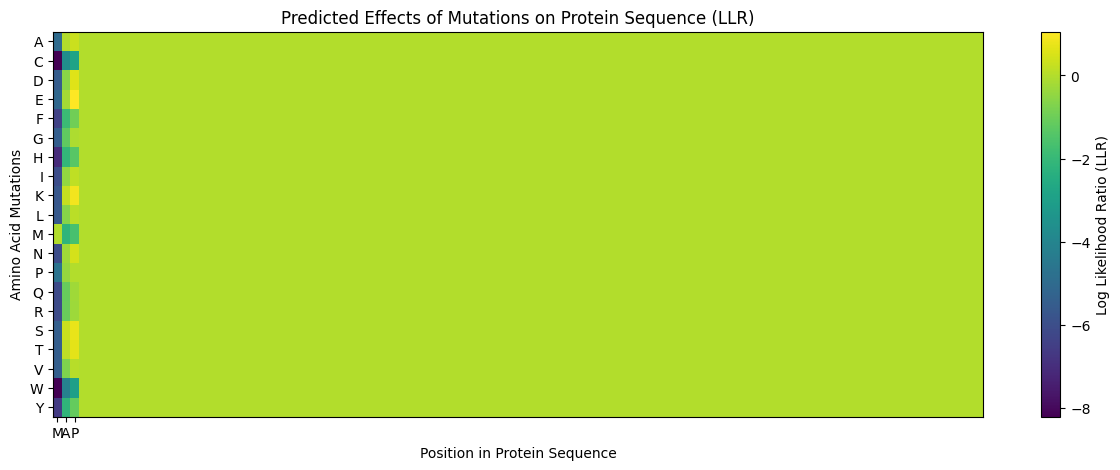

In [ ]:
plt.figure(figsize=(15, 5))
plt.imshow(heatmap, cmap="viridis", aspect="auto")
plt.xticks(range(end_pos - start_pos + 1), list(protein_sequence[start_pos-1:end_pos]))
plt.yticks(range(20), amino_acids)
plt.xlabel("Position in Protein Sequence")
plt.ylabel("Amino Acid Mutations")
plt.title("Predicted Effects of Mutations on Protein Sequence (LLR)")
plt.colorbar(label="Log Likelihood Ratio (LLR)")
plt.savefig('heatmap.png')
plt.show()

## Visualization of LLR Heatmaps from the Paper

The figure below is taken from the paper ["Language models enable zero-shot prediction of the effects of mutations on protein function"](https://www.biorxiv.org/content/10.1101/2021.07.09.450648v2), which illustrates how LLR heatmaps can indicate beneficial versus deleterious mutations for protein function.

![LLR Heatmap from Paper](https://cdn-uploads.huggingface.co/production/uploads/64191ec8d459c9e7fbb0236b/9EeZnYaRt569A3t7GwxiM.png)

### Interpretation of the Heatmap
- **Red areas** represent lower LLR values, suggesting mutations that are potentially deleterious to the protein's function.
- **Blue areas** represent higher LLR values, indicating mutations that could be beneficial or neutral to the protein's function.

This color scheme is somewhat inverted from typical heatmaps where higher values are often represented by warmer colors (e.g., yellow, red) and lower values by cooler colors (e.g., blue).



# GFP Mutations: Log-Likelihood Ratios (LLR) Analysis

## Task:
Analyze the effect of mutations on the GFP protein sequence by calculating Log-Likelihood Ratios (LLR) and visualizing the results using a heatmap. The focus is to understand how specific mutations impact key positions in the GFP protein: **Serine 65 (S65)**, **Tyrosine 66 (Y66)**, and **Glycine 67 (G67)**.

---

## Objectives:
1. Compute masked scores for each residue in the GFP protein sequence.
2. Create a dataset to evaluate model predictions effectively.
3. Generate a heatmap illustrating mutation effects across all positions.
4. Investigate mutation scores specifically for residues **65, 66, and 67**.

---

## Steps:
1. **Compute Masked Scores**:
2. **Prepare the Dataset**:
3. **Model Evaluation**:
4. **Heatmap Visualization**:
5. **Residue-Specific Investigation**:

---

## Expected Outcome:
A comprehensive visualization of mutation effects on GFP, with detailed insights into the functional relevance of residues **S65**, **Y66**, and **G67**.


In [ ]:

gfp_seq = 'MSKGEELFTGVVPILVELDGDVNGHKFSVSGEGEGDATYGKLTLKFICTTGKLPVPWPTLVTTFSYGVQCFSRYPDHMKRHDFFKSAMPEGYVQERTIFFKDDGNYKTRAEVKFEGDTLVNRIELKGIDFKEDGNILGHKLEYNFNSHNVYIMADKQKNGIKANFKIRHNIEDGSVQLADHYQQNTPIGDGPVLLPDNHYLSTQSALSKDPNEKRDHMVLLEFVTAAGITHGMDELYK'
# your code .....

import torch
import esm
import numpy as np
import matplotlib.pyplot as plt
from transformers import AutoTokenizer, EsmForMaskedLM

# Load the ESM model and tokenizer
model_name = "facebook/esm2_t6_8M_UR50D"
tokenizer = AutoTokenizer.from_pretrained(model_name)
model = EsmForMaskedLM.from_pretrained(model_name)

# Define the GFP sequence
protein_sequence = "MSKGEELFTGVVPILVELDGDVNGHKFSVSGEGEGDATYGKLTLKFICTTGKLPVPWPTLVTTFSYGVQCFSRYPDHMKRHDFFKSAMPEGYVQERTIFFKDDGNYKTRAEVKFEGDTLVNRIELKGIDFKEDGNILGHKLEYNFNSHNVYIMADKQKNGIKANFKIRHNIEDGSVQLADHYQQNTPIGDGPVLLPDNHYLSTQSALSKDPNEKRDHMVLLEFVTAAGITHGMDELYK"

# Positions of interest
positions_of_interest = [65, 66, 67]
start_pos = 1

input_ids = tokenizer.encode(protein_sequence, return_tensors="pt")
sequence_length = input_ids.shape[1] - 2
end_pos = sequence_length

input_ids_list = []
start_pos=1




for position in range(start_pos, end_pos + 1):
    # Mask the target position
    masked_input_ids = input_ids.clone()
    masked_input_ids[0, position] = tokenizer.mask_token_id

    #with torch.no_grad():
    #    logits = model(masked_input_ids).logits
    input_ids_list.append(masked_input_ids[0])

# Stacking the updated sequences
batched_input_ids = torch.stack(input_ids_list)


protein_ds = ProteinDataset(batched_input_ids)

batch_size = 2 # It is very small, just for testing purposes
dataloader = DataLoader(protein_ds, batch_size=batch_size)
print(protein_ds[0])
print(len(protein_ds))

logits_ls = []
device = torch.device("cuda")
model.to(device)


for input_ids in dataloader:
    # Since batches are pre-made, input_ids is already a batch
    # Move batch to GPU if not already
    input_ids = input_ids.to('cuda')

    # Run model inference
    with torch.no_grad():
        output = model(input_ids)
        logits = output.logits.cpu()  # Move logits to CPU
        logits_ls.append(logits)  # Convert to NumPy array
all_logits = torch.concatenate(logits_ls, axis=0)
all_logits.shape







tensor([ 0, 32,  8, 15,  6,  9,  9,  4, 18, 11,  6,  7,  7, 14, 12,  4,  7,  9,
         4, 13,  6, 13,  7, 17,  6, 21, 15, 18,  8,  7,  8,  6,  9,  6,  9,  6,
        13,  5, 11, 19,  6, 15,  4, 11,  4, 15, 18, 12, 23, 11, 11,  6, 15,  4,
        14,  7, 14, 22, 14, 11,  4,  7, 11, 11, 18,  8, 19,  6,  7, 16, 23, 18,
         8, 10, 19, 14, 13, 21, 20, 15, 10, 21, 13, 18, 18, 15,  8,  5, 20, 14,
         9,  6, 19,  7, 16,  9, 10, 11, 12, 18, 18, 15, 13, 13,  6, 17, 19, 15,
        11, 10,  5,  9,  7, 15, 18,  9,  6, 13, 11,  4,  7, 17, 10, 12,  9,  4,
        15,  6, 12, 13, 18, 15,  9, 13,  6, 17, 12,  4,  6, 21, 15,  4,  9, 19,
        17, 18, 17,  8, 21, 17,  7, 19, 12, 20,  5, 13, 15, 16, 15, 17,  6, 12,
        15,  5, 17, 18, 15, 12, 10, 21, 17, 12,  9, 13,  6,  8,  7, 16,  4,  5,
        13, 21, 19, 16, 16, 17, 11, 14, 12,  6, 13,  6, 14,  7,  4,  4, 14, 13,
        17, 21, 19,  4,  8, 11, 16,  8,  5,  4,  8, 15, 13, 14, 17,  9, 15, 10,
        13, 21, 20,  7,  4,  4,  9, 18, 

torch.Size([238, 240, 33])

In [ ]:
end_pos=237
start_pos = 0
heatmap = np.zeros((20, end_pos - start_pos + 1))
for idx, position in enumerate(range(start_pos, end_pos + 1)):

    logits = all_logits[idx]
    probabilities = torch.nn.functional.softmax(logits[position,:], dim=0)
    log_probabilities = torch.log(probabilities)
    wt_residue_index = aa2esmid[protein_sequence[position-start_pos]]
    log_prob_wt = log_probabilities[wt_residue_index].item()
    print(f'position: {position}, wt_residue: {protein_sequence[position-start_pos]}' )

    for aa in amino_acids:
        esm_idx = aa2esmid[aa]
        aa_idx = aa2heatmap_idx[aa]
        log_prob_mt = log_probabilities[esm_idx].item()
        heatmap[aa_idx, position - start_pos] = log_prob_mt - log_prob_wt


position: 0, wt_residue: M
position: 1, wt_residue: S
position: 2, wt_residue: K
position: 3, wt_residue: G
position: 4, wt_residue: E
position: 5, wt_residue: E
position: 6, wt_residue: L
position: 7, wt_residue: F
position: 8, wt_residue: T
position: 9, wt_residue: G
position: 10, wt_residue: V
position: 11, wt_residue: V
position: 12, wt_residue: P
position: 13, wt_residue: I
position: 14, wt_residue: L
position: 15, wt_residue: V
position: 16, wt_residue: E
position: 17, wt_residue: L
position: 18, wt_residue: D
position: 19, wt_residue: G
position: 20, wt_residue: D
position: 21, wt_residue: V
position: 22, wt_residue: N
position: 23, wt_residue: G
position: 24, wt_residue: H
position: 25, wt_residue: K
position: 26, wt_residue: F
position: 27, wt_residue: S
position: 28, wt_residue: V
position: 29, wt_residue: S
position: 30, wt_residue: G
position: 31, wt_residue: E
position: 32, wt_residue: G
position: 33, wt_residue: E
position: 34, wt_residue: G
position: 35, wt_residue: D
po

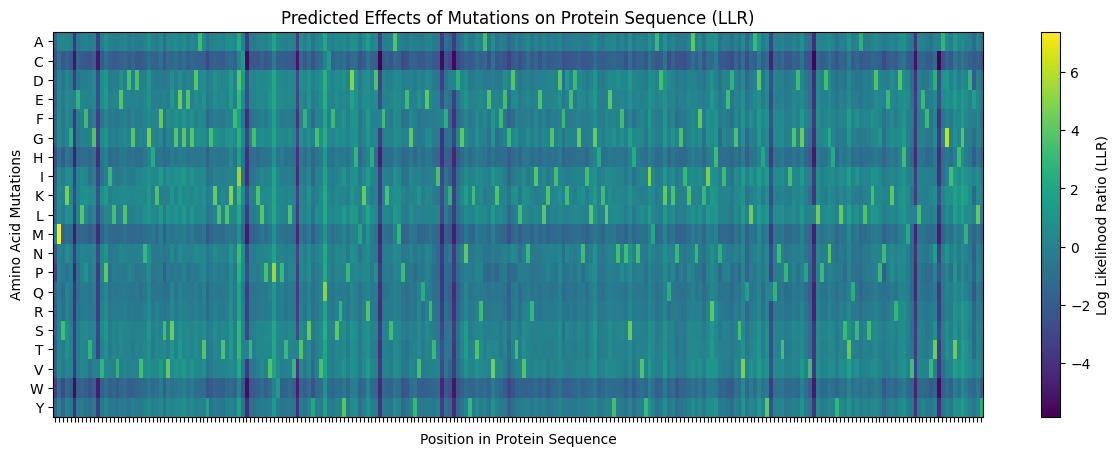

In [ ]:
plt.figure(figsize=(15, 5))
plt.imshow(heatmap, cmap="viridis", aspect="auto")
plt.xticks(range(end_pos - start_pos + 1), list(protein_sequence[start_pos-1:end_pos]))
plt.yticks(range(20), amino_acids)
plt.xlabel("Position in Protein Sequence")
plt.ylabel("Amino Acid Mutations")
plt.title("Predicted Effects of Mutations on Protein Sequence (LLR)")
plt.colorbar(label="Log Likelihood Ratio (LLR)")
plt.savefig('heatmap.png')
plt.show()


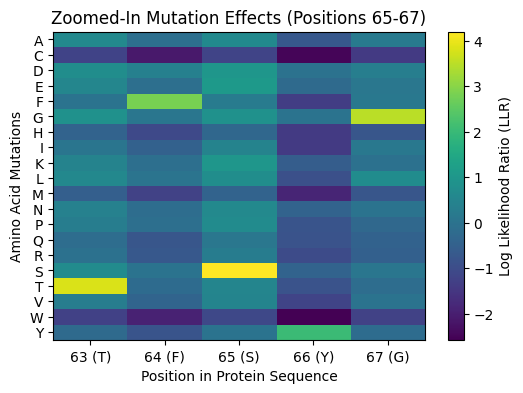

In [ ]:
# Define positions of interest and extract WT residues
focus_positions = [63, 64, 65, 66, 67]
wt_residues = [protein_sequence[pos - 1] for pos in focus_positions]  # Extract WT residues (1-based indexing)

# Update heatmap zoom
heatmap_zoom = heatmap[:, [pos - start_pos for pos in focus_positions]]

# Update x-axis labels to include WT residues
x_labels = [f"{pos} ({res})" for pos, res in zip(focus_positions, wt_residues)]

# Plot zoomed-in heatmap
plt.figure(figsize=(6, 4))
plt.imshow(heatmap_zoom, cmap="viridis", aspect="auto")
plt.xticks(range(len(focus_positions)), x_labels)  # Use updated x-axis labels
plt.yticks(range(20), amino_acids)
plt.xlabel("Position in Protein Sequence")
plt.ylabel("Amino Acid Mutations")
plt.title("Zoomed-In Mutation Effects (Positions 65-67)")
plt.colorbar(label="Log Likelihood Ratio (LLR)")
plt.show()



## Protein Design and Optimization

Protein design can be approached by evaluating the **fitness** of a sequence, defined as the aggregate pseudo log-likelihood of its amino acids. By comparing the fitness of the wild-type (WT) sequence with potential variants, we can propose substitutions that increase predicted protein quality.

### Definitions

- **Pseudo log-likelihood at position $i$:**

$$
\text{PLL}_i(a) = \log p_\theta(a \mid x_{\setminus i})
$$

where $x_{\setminus i}$ is the sequence with position $i$ masked, and $a$ is a candidate amino acid.

- **Log-likelihood ratio (LLR):**

$$
\text{LLR}_i(a) = \text{PLL}_i(a) - \text{PLL}_i(w_i)
$$

where $w_i$ is the wild-type residue at position $i$.

- **Sequence fitness (pseudo log-likelihood):**

$$
\mathcal{F}(x) = \sum_{i=1}^{L} \text{PLL}_i(x_i)
$$

- **Delta fitness for a candidate sequence $y$:**

$$
\Delta \mathcal{F}(y; x) = \sum_{i=1}^{L} \text{LLR}_i(y_i)
$$

### Objectives

1. **Implement a fitness function**  
   Compute $\mathcal{F}(x)$ by masking each position once, reading the model’s logits, converting them to probabilities, and summing $\text{PLL}_i(x_i)$ over all positions.

2. **Propose an optimized sequence**  
   - For each position, find the amino acid $a^\star_i$ that maximizes $\text{LLR}_i(a)$.  
   - Keep substitutions where $\text{LLR}_i(a^\star_i) > 0$.  
   - Optionally, apply the best substitution(s) iteratively, recomputing PLLs to account for context.

3. **Report results**  
   - Compare WT fitness $\mathcal{F}(x)$ and optimized fitness $\mathcal{F}(y)$.  
   - Show the list of proposed substitutions with their $\text{LLR}_i$ values.  
   - Visualize top beneficial sites with a bar plot or sequence map.

### Limitations

Think about the potential limitations.



# Embedding Visualization

## What are Embeddings?
Embeddings are numerical representations of data that capture the underlying characteristics and relationships in a lower-dimensional vector space. For protein sequences, embeddings map each sequence into a high-dimensional vector space where sequences with similar properties are closer to each other.

In the case of protein sequences, **embeddings are position-specific**. That means each position in the sequence (each amino acid) has a unique embedding vector that represents its features based on the sequence context.

**Formal Definition**:  
An embedding is a function $f: X \to \mathbb{R}^d$, where $X$ is the original data space (e.g., protein sequences) and $\mathbb{R}^d$ is the $d$-dimensional embedding space. The function $f$ is typically learned by a model like ESM, and $d$ is the size of the embedding vector. These embeddings are position-specific, meaning that for each residue in a sequence, there is a corresponding embedding vector in the output.

### Output Dimensions of ESM Models
The output dimensions of ESM models depend on the specific model variant used. For example:
- **ESM2 (e.g., `esm2_t6_8M_UR50D`)** generates **[sequence length, hidden size]** embeddings, where the hidden size is typically **320** for the `esm2_t6_8M_UR50D` model.

Thus, for a sequence of length $n$, the output from the model will be a tensor of shape $[n, 320]$, where each row is a position-specific embedding of the sequence.

---

## What is Pooling?
Pooling is an operation that aggregates features along a specific axis (e.g., the sequence axis for proteins). Since the embeddings generated by models like ESM are position-specific, pooling is needed to summarize these position-specific embeddings into a single vector representing the entire sequence.

**Why Pooling is Needed**:
The output embeddings of a protein sequence are position-specific, meaning that each residue (amino acid) in the sequence has its own embedding vector. However, to make use of these embeddings for tasks like classification or clustering, we need a single vector representation for the entire sequence. Pooling aggregates these position-specific embeddings into a fixed-size vector, which allows the downstream task to use this information.

**Types of Pooling**:
1. **Mean Pooling**: Computes the average value for each dimension:
   $$
   \text{Mean Pooling}: \quad \mathbf{v}_\text{mean} = \frac{1}{n} \sum_{i=1}^n \mathbf{v}_i
   $$
   where $\mathbf{v}_i$ represents the embedding for each residue and $n$ is the sequence length.

2. **Max Pooling**: Takes the maximum value along each dimension:
   $$
   \text{Max Pooling}: \quad \mathbf{v}_\text{max} = \max_{i=1}^n \mathbf{v}_i
   $$

3. **Min Pooling**: Takes the minimum value along each dimension:
   $$
   \text{Min Pooling}: \quad \mathbf{v}_\text{min} = \min_{i=1}^n \mathbf{v}_i
   $$

Pooling strategies provide different perspectives on the sequence representation. For example, max pooling highlights the most dominant features, while mean pooling provides an overall summary.

---

## Dataset Description
The dataset contains information about protein sequences and their subcellular localization. It consists of the following columns:

1. **Protein ID**: A unique identifier for each protein sequence.
2. **Localization**: The subcellular location of the protein (e.g., Lysosome/Vacuole).
3. **Full Header**: The complete FASTA header, including descriptive information.
4. **Sequence**: The amino acid sequence of the protein.
5. **Is Test**: A boolean flag indicating whether the sequence was marked as a test sequence.

This dataset is suitable for tasks like training models to predict protein localization based on sequence embeddings.

---

## What is UMAP?
UMAP (Uniform Manifold Approximation and Projection) is a dimensionality reduction technique used to project high-dimensional data into a lower-dimensional space, typically 2D or 3D, for visualization and clustering.

**Key Characteristics**:
- UMAP preserves the global structure of the data while optimizing local neighborhoods.
- It is often used for visualization and discovering patterns in high-dimensional data.

---

### UMAP Parameters
1. **`n_neighbors`**:
   - Defines the number of neighboring points considered when constructing the local structure.
   - Larger values emphasize global structure, while smaller values focus on local patterns.
   - Typical range: $5$–$50$.

2. **`min_dist`**:
   - Controls how tightly UMAP clusters points in the lower-dimensional space.
   - Smaller values produce more compact clusters; larger values spread points more evenly.
   - Typical range: $0.001$–$0.5$.

3. **`n_components`**:
   - Specifies the dimensionality of the reduced space (e.g., 2D or 3D).
   - Commonly used values are $2$ (for visualization) or $3$.

4. **`random_state`**:
   - A seed for reproducibility of the UMAP projections.

---

## Steps for Embedding Visualization
1. **Compute Embeddings**:
   - Use a pre-trained model like ESM to generate per-residue embeddings for each protein sequence.
   - Apply a pooling strategy (mean, max, or min pooling) to summarize the embeddings for the entire sequence.

2. **Apply UMAP**:
   - Reduce the dimensionality of the sequence embeddings to 2 or 3 dimensions using UMAP.
   - Experiment with different `n_neighbors` and `min_dist` values to optimize the visualization.

3. **Visualize the Embeddings**:
   - Create a scatter plot of the UMAP embeddings.
   - Color the points based on the protein localization to analyze clustering patterns.


In [ ]:
dataset

DatasetDict({
    train: Dataset({
        features: ['Protein ID', 'Localization', 'Full Header', 'Sequence', 'Is Test'],
        num_rows: 5959
    })
})

In [ ]:
from datasets import load_dataset
from transformers import AutoTokenizer, EsmForMaskedLM
from torch.utils.data import DataLoader
import umap
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import torch
from tqdm import tqdm
from datasets import *

# Load the dataset from Hugging Face
dataset = load_dataset("neuralbioinfo/Course-ProteinLoc")

# Initialize tokenizer and model
model_name = "facebook/esm2_t6_8M_UR50D"
tokenizer = AutoTokenizer.from_pretrained(model_name)
model = EsmForMaskedLM.from_pretrained(model_name)
model.eval()
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model.to(device)

# Tokenize the dataset
def tokenize_function(examples):
    return tokenizer(
        examples["Sequence"],
        truncation=True,
        padding="max_length",
        max_length=512,
        return_tensors="pt"
    )

# Tokenize and format dataset for PyTorch DataLoader
tokenized_dataset = dataset.map(
    tokenize_function,
    batched=True,
    remove_columns=["Sequence"]
)
tokenized_dataset.set_format(type="torch", columns=["input_ids", "attention_mask", "Localization"])

# Create DataLoader
batch_size = 16
dataloader = DataLoader(tokenized_dataset["train"], batch_size=batch_size, shuffle=False)


In [ ]:
# Extract embeddings
embeddings = []
labels = []

with torch.no_grad():
    for batch in tqdm(dataloader):
        input_ids = batch["input_ids"].to(device)
        attention_mask = batch["attention_mask"].to(device)
        batch_labels = batch["Localization"]

        # Forward pass
        outputs = model.base_model(input_ids=input_ids, attention_mask=attention_mask)
        hidden_states = outputs.last_hidden_state  # Shape: [Batch Size, Sequence Length, Hidden Size]

        # Mean pooling over sequence length
        mean_pooled = hidden_states.mean(dim=1).cpu().numpy()  # Shape: [Batch Size, Hidden Size]

        embeddings.extend(mean_pooled)  # Store embeddings
        labels.extend(batch_labels)  # Store labels

# Convert embeddings and labels to NumPy arrays
embeddings = np.array(embeddings)
labels = np.array(labels)
embeddings.shape


  0%|          | 0/373 [00:00<?, ?it/s]

(5959, 320)

In [ ]:
# Adjust UMAP parameters
umap_model = umap.UMAP(n_neighbors=15, min_dist=0.3, n_components=2, random_state=42)
umap_embeddings = umap_model.fit_transform(embeddings)


/usr/local/lib/python3.12/dist-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


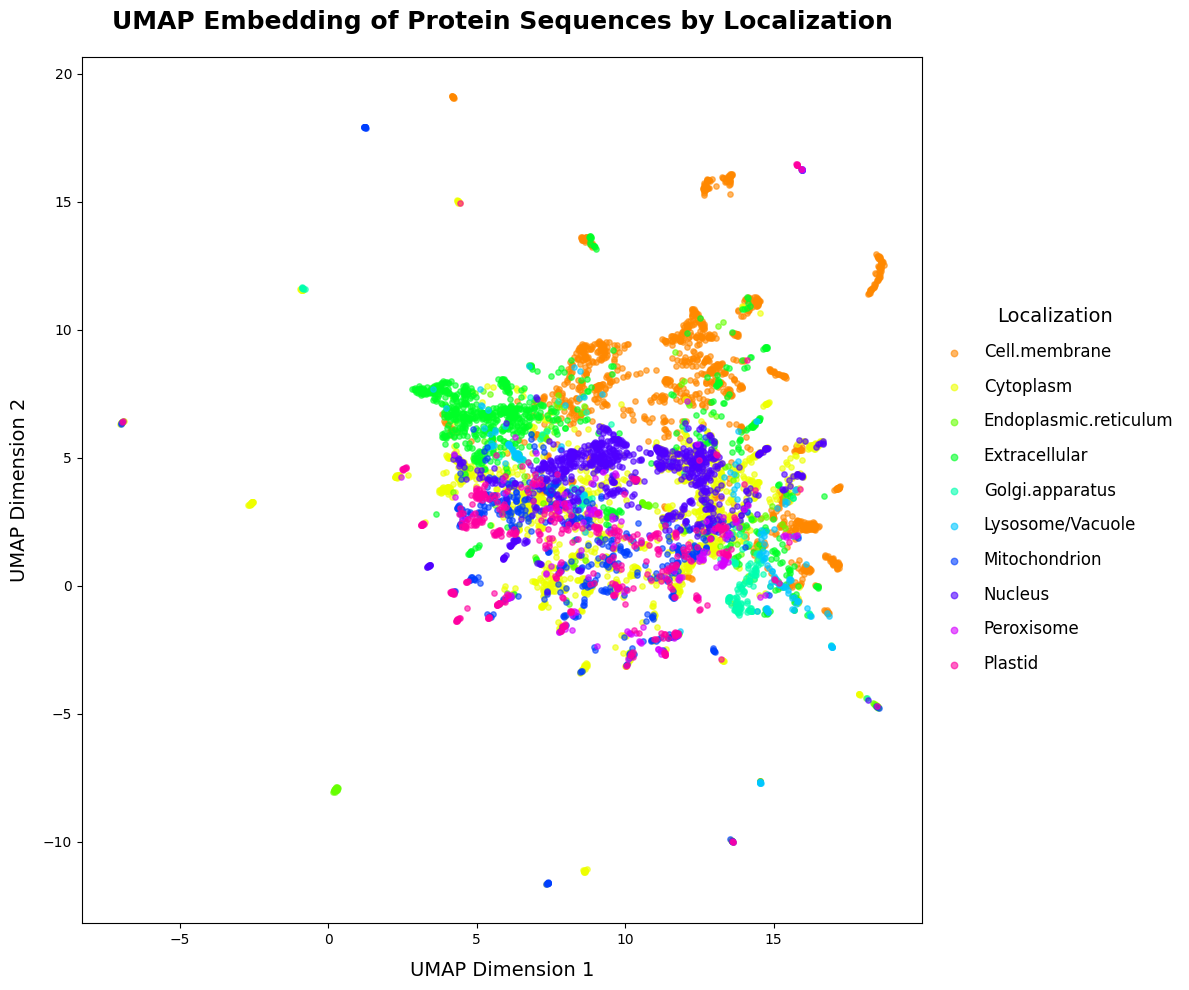

In [ ]:
plt.figure(figsize=(12, 10))  # Larger figure for clarity

unique_labels = np.unique(labels)
palette = sns.color_palette("hsv", n_colors=len(unique_labels))  # Colorful and visually distinct

for label, color in zip(unique_labels, palette):
    indices = labels == label
    plt.scatter(
        umap_embeddings[indices, 0],
        umap_embeddings[indices, 1],
        label=label,
        s=15,
        alpha=0.6,
        color=color
    )

# Add title and axis labels with improved font size and weight
plt.title("UMAP Embedding of Protein Sequences by Localization", fontsize=18, fontweight="bold", pad=20)
plt.xlabel("UMAP Dimension 1", fontsize=14, labelpad=10)
plt.ylabel("UMAP Dimension 2", fontsize=14, labelpad=10)

# Improve legend formatting
plt.legend(
    loc="center left",
    bbox_to_anchor=(1, 0.5),
    fontsize=12,  # Larger font size for legend items
    title="Localization",
    title_fontsize=14,  # Larger font size for legend title
    markerscale=1.2,  # Slightly smaller marker size in legend
    labelspacing=1.0,  # Less spacing between legend items
    frameon=False  # No frame for a cleaner look
)

# Adjust layout to fit legend and plot properly
plt.tight_layout()

# Show the improved plot
plt.show()

# Task: Comparing Mean, Max, and Min Pooling for Protein Embeddings

## Objective
Your task is to investigate the effect of different pooling strategies (Mean, Max, and Min pooling) on the visualization of protein sequence embeddings. By applying these pooling methods to the last hidden state of the ESM model, you will generate UMAP plots for each pooling strategy and compare their clustering performance.

---

## Steps to Complete the Task

1. **Extract Embeddings**:
   - Use the **last hidden state** of the ESM model as the starting point.
   - For each protein sequence in the dataset, apply **Mean**, **Max**, and **Min pooling** over the sequence dimension.

2. **Apply UMAP**:
   - For each pooling method (Mean, Max, Min), reduce the dimensionality of the pooled embeddings using UMAP.

3. **Generate Plots**:
   - Create separate UMAP plots for each pooling strategy.
   - Use different colors to represent the protein localization labels.

4. **Compare and Analyze**:
   - Compare the clustering patterns across the three pooling strategies.
   - Discuss how different pooling methods affect the clustering quality and interpretability of the embeddings.

---

## Questions to Answer

1. **Visualization**:
   - How do the clusters differ across Mean, Max, and Min pooling UMAP plots?
   - Are any pooling strategies better at separating localization classes?

2. **Clustering Quality**:
   - Which pooling strategy creates the most compact clusters?
   - Which pooling strategy separates distinct classes most clearly?

3. **Interpretability**:
   - Which pooling method provides the most meaningful embedding visualization for this task?


In [ ]:
5+5

10

100%|██████████| 373/373 [00:46<00:00,  7.96it/s]
/usr/local/lib/python3.12/dist-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


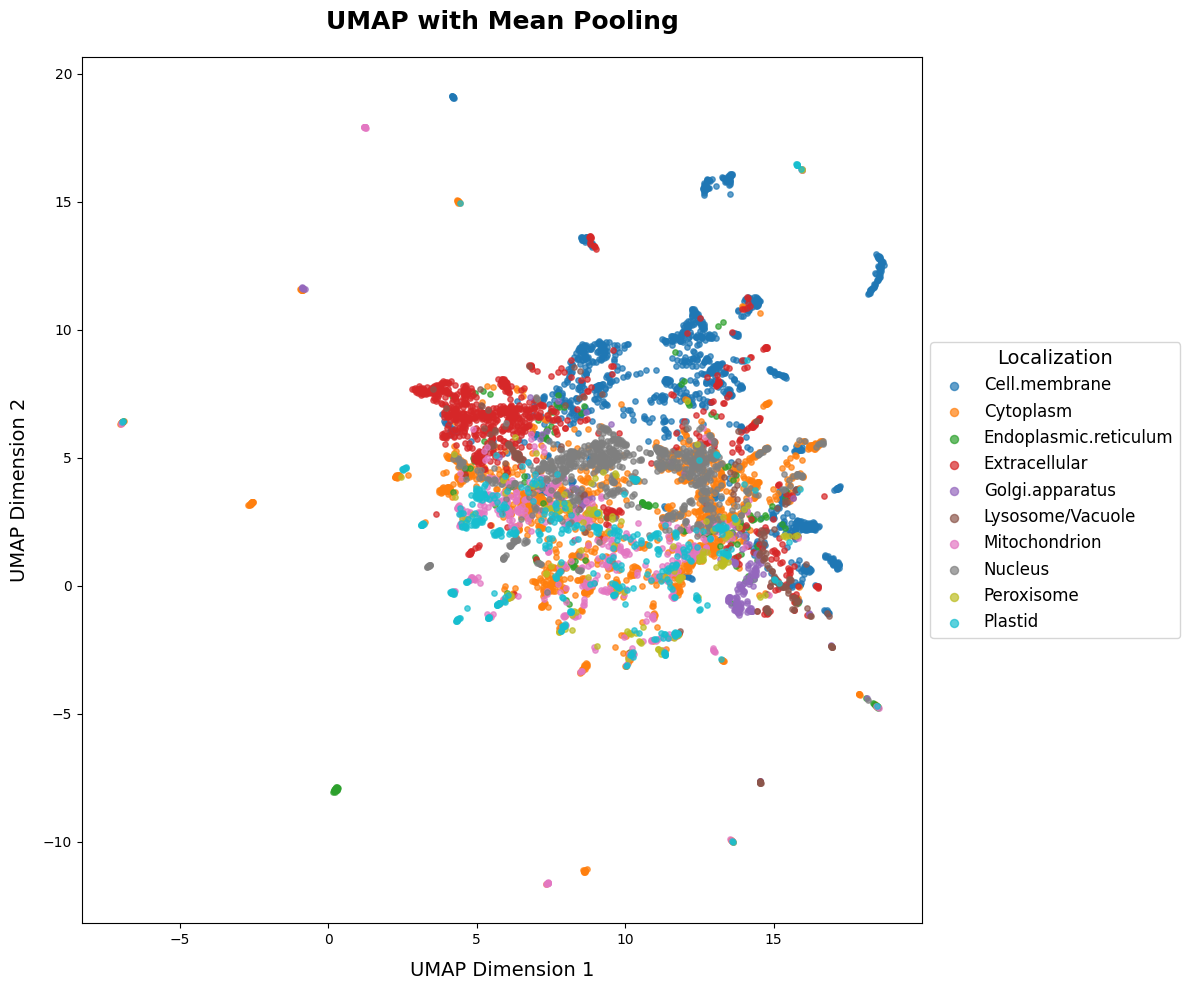

/usr/local/lib/python3.12/dist-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


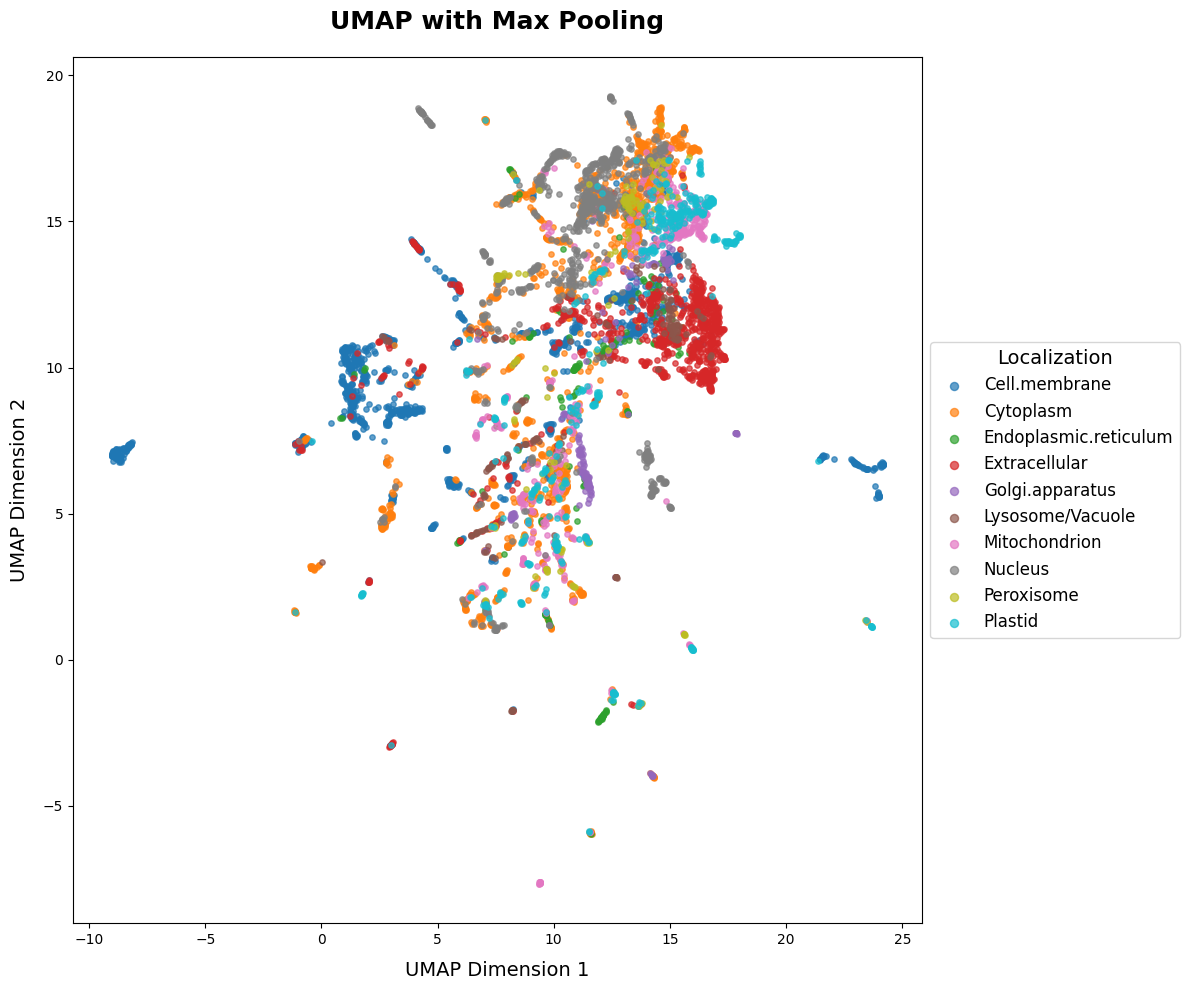

/usr/local/lib/python3.12/dist-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


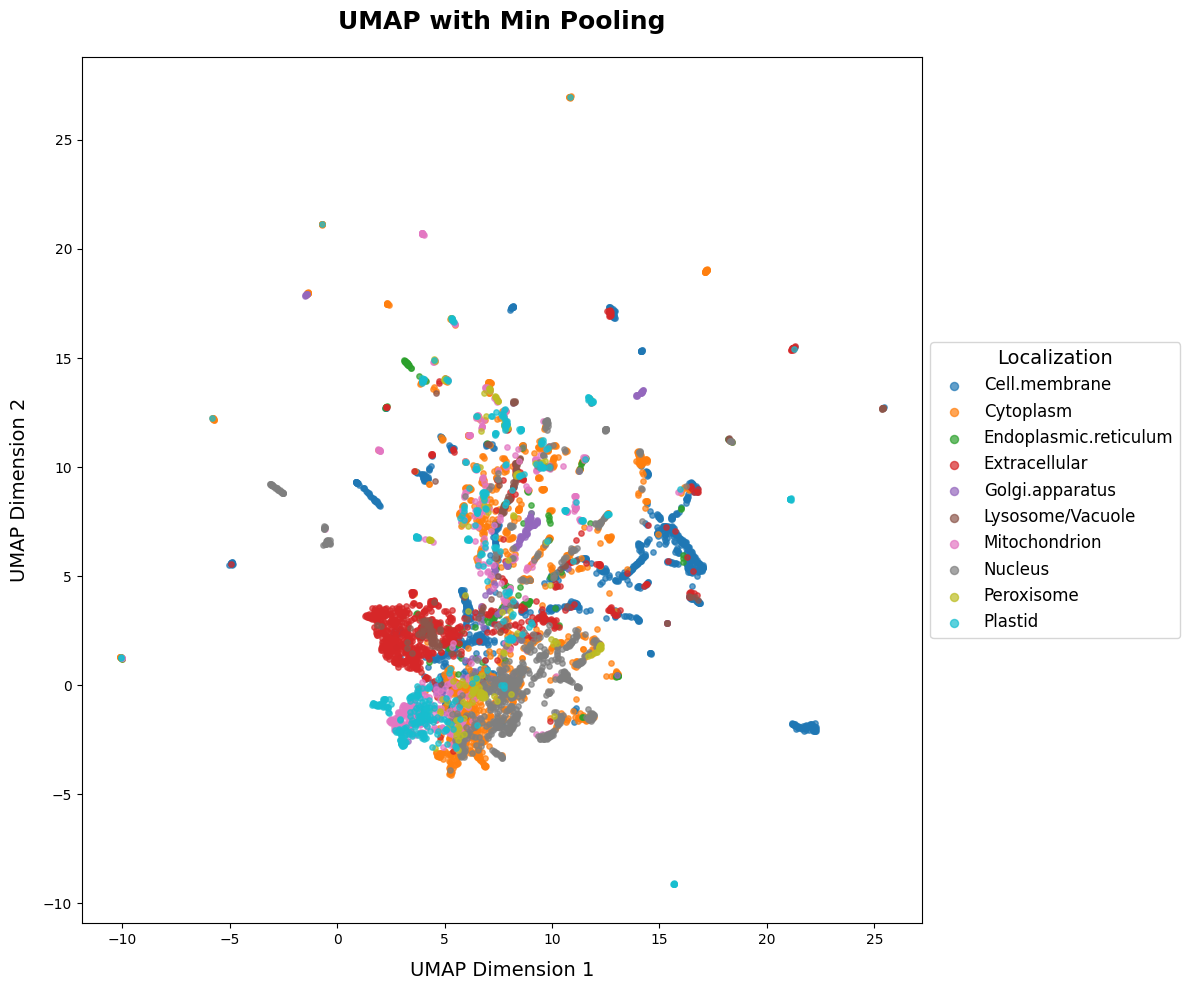

In [ ]:
# Solution
# Solution
from datasets import load_dataset
from transformers import AutoTokenizer, EsmForMaskedLM
from torch.utils.data import DataLoader
import umap
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import torch
from tqdm import tqdm

# Load the dataset from Hugging Face
dataset = load_dataset("neuralbioinfo/Course-ProteinLoc")

# Initialize tokenizer and model
model_name = "facebook/esm2_t6_8M_UR50D"
tokenizer = AutoTokenizer.from_pretrained(model_name)
model = EsmForMaskedLM.from_pretrained(model_name)
model.eval()
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model.to(device)

# Tokenize the dataset
def tokenize_function(examples):
    return tokenizer(
        examples["Sequence"],
        truncation=True,
        padding="max_length",
        max_length=512,
        return_tensors="pt"
    )

# Tokenize and format dataset for PyTorch DataLoader
tokenized_dataset = dataset.map(
    tokenize_function,
    batched=True,
    remove_columns=["Sequence"]
)
tokenized_dataset.set_format(type="torch", columns=["input_ids", "attention_mask", "Localization"])

# Create DataLoader
batch_size = 16
dataloader = DataLoader(tokenized_dataset["train"], batch_size=batch_size, shuffle=False)

# Extract embeddings with Mean, Max, and Min pooling
mean_embeddings = []
max_embeddings = []
min_embeddings = []
labels = []

with torch.no_grad():
    for batch in tqdm(dataloader):
        input_ids = batch["input_ids"].to(device)
        attention_mask = batch["attention_mask"].to(device)
        batch_labels = batch["Localization"]

        # Forward pass
        outputs = model.base_model(input_ids=input_ids, attention_mask=attention_mask)
        hidden_states = outputs.last_hidden_state  # Shape: [Batch Size, Sequence Length, Hidden Size]

        # Pooling
        mean_pooled = hidden_states.mean(dim=1).cpu().numpy()  # Shape: [Batch Size, Hidden Size]
        max_pooled = hidden_states.max(dim=1).values.cpu().numpy()  # Shape: [Batch Size, Hidden Size]
        min_pooled = hidden_states.min(dim=1).values.cpu().numpy()  # Shape: [Batch Size, Hidden Size]

        # Store embeddings and labels
        mean_embeddings.extend(mean_pooled)
        max_embeddings.extend(max_pooled)
        min_embeddings.extend(min_pooled)
        labels.extend(batch_labels)

# Convert embeddings and labels to NumPy arrays
mean_embeddings = np.array(mean_embeddings)
max_embeddings = np.array(max_embeddings)
min_embeddings = np.array(min_embeddings)
labels = np.array(labels)

# Function to generate UMAP plots
def plot_umap(embeddings, labels, title, n_neighbors=15, min_dist=0.3):
    umap_model = umap.UMAP(n_neighbors=n_neighbors, min_dist=min_dist, n_components=2, random_state=42)
    umap_embeddings = umap_model.fit_transform(embeddings)

    plt.figure(figsize=(12, 10))
    unique_labels = np.unique(labels)
    palette = sns.color_palette("tab10", n_colors=len(unique_labels))

    for label, color in zip(unique_labels, palette):
        indices = labels == label
        plt.scatter(
            umap_embeddings[indices, 0],
            umap_embeddings[indices, 1],
            label=label,
            s=15,  # Smaller dot size
            alpha=0.7,  # Transparency
            color=color
        )

    plt.title(title, fontsize=18, fontweight="bold", pad=20)
    plt.xlabel("UMAP Dimension 1", fontsize=14, labelpad=10)
    plt.ylabel("UMAP Dimension 2", fontsize=14, labelpad=10)
    plt.legend(
        loc="center left",
        bbox_to_anchor=(1, 0.5),
        fontsize=12,
        title="Localization",
        title_fontsize=14,
        markerscale=1.5
    )
    plt.tight_layout()
    plt.show()

# Generate and display UMAP plots for each pooling method
plot_umap(mean_embeddings, labels, "UMAP with Mean Pooling")
plot_umap(max_embeddings, labels, "UMAP with Max Pooling")
plot_umap(min_embeddings, labels, "UMAP with Min Pooling")








# Fine-Tuning Task: Protein Localization Classification

## **Introduction to Fine-Tuning and Transfer Learning**
Fine-tuning is a transfer learning technique where a pre-trained model is adapted to a specific task using labeled data from a target domain. In this task, we fine-tune the ESM (Evolutionary Scale Modeling) model, which has been pre-trained on large protein sequence datasets, for the classification of protein subcellular localization.

### **Why Transfer Learning?**
Pre-trained models like ESM capture general-purpose sequence representations, including biological features. Fine-tuning these models enables:
1. **Faster Convergence**: Leveraging pre-trained weights reduces the need for extensive training from scratch.
2. **Improved Accuracy**: Pre-training on massive datasets helps the model generalize better, even with limited labeled data in the target task.
3. **Efficient Resource Usage**: Reduces computational costs by reusing existing learned features.

---

## **Task Description**
We aim to classify proteins into their respective subcellular localization categories using their amino acid sequences.

### Steps:
1. **Data Preparation**:
   - Tokenize protein sequences using the ESM tokenizer.
   - Encode labels for the localization categories.
   - Split the dataset into training, validation, and test sets.

2. **Fine-Tune the ESM Model**:
   - Add a classification head on top of the pre-trained ESM backbone.
   - Use the training dataset to fine-tune the model parameters.
   - Monitor the model’s performance on the validation dataset during training.

3. **Evaluate the Model**:
   - Evaluate the fine-tuned model on the test dataset.
   - Measure accuracy and other performance metrics.

---

## **Optimization Goal**

The goal of optimization is to minimize the loss function, which represents the difference between the model’s predictions and the true labels. For this classification task, we use the **cross-entropy loss** function.

---

## **Fine-Tuning Steps**

### **Step 1: Data Preparation**
1. **Tokenization**:
   Convert protein sequences into tokenized inputs using the ESM tokenizer. Each sequence is padded or truncated to a fixed length (e.g., 512 tokens).
2. **Label Encoding**:
   Map localization categories to numeric labels (e.g., Cytoplasm = 0, Nucleus = 1).
3. **Dataset Splits**:
   - **Training Set**: Used to update the model’s weights during fine-tuning.
   - **Validation Set**: Used to evaluate the model during training and select the best-performing version.
   - **Test Set**: Used for final evaluation after training.

---

### **Step 2: Model Setup**
1. **Pre-Trained Backbone**:
   - Load the ESM pre-trained model.
   - The model has already learned general protein sequence features.
2. **Classification Head**:
   - Add a fully connected layer on top of the ESM model to output probabilities for each localization class.
3. **Optimization Function**:
   - Use the AdamW optimizer to minimize the cross-entropy loss.
   - Learning rate: $5 \times 10^{-5}$
   - Weight decay: $0.01$

---

### **Step 3: Training**
- Train the model for a small number of epochs (e.g., 5) with a batch size of 16.
- Monitor the accuracy on the validation dataset after each epoch.
- Save the best-performing model based on validation accuracy.

---

### **Step 4: Evaluation**
1. **Metrics**:
   - **Accuracy**: Proportion of correctly classified samples.
   - **Confusion Matrix**: Analyze class-specific performance.
   - **Precision, Recall, F1-Score**: Assess performance for individual classes.
2. **Baseline Comparison**:
   - Random predictions.



## Dataset and model preparations


In [ ]:
from datasets import load_dataset
from transformers import AutoTokenizer, EsmForSequenceClassification, TrainingArguments, Trainer
from torch.utils.data import DataLoader
import torch
from sklearn.metrics import accuracy_score, classification_report

def compute_metrics(eval_pred):
    logits, labels = eval_pred
    predictions = torch.argmax(torch.tensor(logits), dim=-1).numpy()
    acc = accuracy_score(labels, predictions)
    return {"accuracy": acc}

def encode_labels(example):
    example["labels"] = label_to_id[example["Localization"]]
    return example


# Load the dataset from Hugging Face
dataset = load_dataset("neuralbioinfo/Course-ProteinLoc")

# Split into train, validation, and test sets
split_dataset = dataset["train"].train_test_split(test_size=0.2, seed=42)  # 80% train, 20% test
train_val_split = split_dataset["train"].train_test_split(test_size=0.25, seed=42)  # 75% of 80% for train, 25% for val

# Combine splits into a DatasetDict
final_dataset = DatasetDict({
    "train": train_val_split["train"],
    "validation": train_val_split["test"],
    "test": split_dataset["test"]
})

# Apply tokenization to all splits
tokenized_dataset = final_dataset.map(tokenize_function, batched=True)

# Label encoding
label_list = list(dataset["train"].unique("Localization"))
label_to_id = {label: idx for idx, label in enumerate(label_list)}
id_to_label = {idx: label for label, idx in label_to_id.items()}

# Encode labels


# Apply label encoding
tokenized_dataset = tokenized_dataset.map(encode_labels)

# Format dataset for PyTorch
tokenized_dataset.set_format(type="torch", columns=["input_ids", "attention_mask", "labels"])

# Split into PyTorch-friendly datasets
train_dataset = tokenized_dataset["train"]
val_dataset = tokenized_dataset["validation"]
test_dataset = tokenized_dataset["test"]

# Load the ESM model for sequence classification
model = EsmForSequenceClassification.from_pretrained(
    "facebook/esm2_t6_8M_UR50D",
    num_labels=len(label_list),  # Number of classes
    id2label=id_to_label,  # Mapping from IDs to labels
    label2id=label_to_id   # Mapping from labels to IDs
)


Map:   0%|          | 0/3575 [00:00<?, ? examples/s]

Map:   0%|          | 0/1192 [00:00<?, ? examples/s]

Map:   0%|          | 0/1192 [00:00<?, ? examples/s]

Map:   0%|          | 0/3575 [00:00<?, ? examples/s]

Map:   0%|          | 0/1192 [00:00<?, ? examples/s]

Map:   0%|          | 0/1192 [00:00<?, ? examples/s]

Some weights of EsmForSequenceClassification were not initialized from the model checkpoint at facebook/esm2_t6_8M_UR50D and are newly initialized: ['classifier.dense.bias', 'classifier.dense.weight', 'classifier.out_proj.bias', 'classifier.out_proj.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


In [ ]:
# What about a random classification:import numpy as np
from sklearn.metrics import accuracy_score

# Random predictions
num_classes = len(label_list)
random_predictions = np.random.randint(0, num_classes, size=len(val_dataset))

true_labels = [example["labels"] for example in val_dataset]

# Calculate accuracy
random_baseline_accuracy = accuracy_score(true_labels, random_predictions)
print(f"Random Baseline Accuracy: {random_baseline_accuracy:.4f}")


Random Baseline Accuracy: 0.1065


## Training

In [ ]:
# Training arguments
training_args = TrainingArguments(
    output_dir="./results",
    evaluation_strategy="epoch",
    save_strategy="epoch",
    learning_rate=5e-5,
    per_device_train_batch_size=16,
    per_device_eval_batch_size=16,
    num_train_epochs=0.5,
    weight_decay=0.01,
    report_to="none",
    #logging_dir="./logs",
    load_best_model_at_end=True,
    #metric_for_best_model="accuracy"
)

# Initialize the Trainer
trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=train_dataset,
    eval_dataset=val_dataset,
    tokenizer=tokenizer,
    compute_metrics=compute_metrics
)

# Train the model
trainer.train()

# Evaluate on the test set
trainer.evaluate(test_dataset)


/usr/local/lib/python3.12/dist-packages/transformers/training_args.py:1575: FutureWarning: `evaluation_strategy` is deprecated and will be removed in version 4.46 of 🤗 Transformers. Use `eval_strategy` instead
  warnings.warn(
/tmp/ipython-input-555077654.py:18: FutureWarning: `tokenizer` is deprecated and will be removed in version 5.0.0 for `Trainer.__init__`. Use `processing_class` instead.
  trainer = Trainer(


Epoch,Training Loss,Validation Loss,Accuracy
0,No log,1.597964,0.634228


{'eval_loss': 1.589660406112671,
 'eval_accuracy': 0.62248322147651,
 'eval_runtime': 9.3178,
 'eval_samples_per_second': 127.927,
 'eval_steps_per_second': 8.049,
 'epoch': 0.5}

# Exercise: Investigating the Impact of Hyperparameters on Model Performance


1. **Baseline Setup**:
   - Use the current training setup as the baseline:
     - Learning rate: $5 \times 10^{-5}$
     - Batch size: 16
     - Weight decay: $0.01$
     - Number of epochs: 5
   - Record the baseline performance metrics (accuracy, precision, recall, F1-score).


2. **Hyperparameter Variations**:
   - Modify one hyperparameter at a time to evaluate its impact on performance. Suggested hyperparameters to change:
     - **Learning Rate**: Experiment with values such as $1 \times 10^{-5}$, $1 \times 10^{-4}$, $1 \times 10^{-3}$.
     - **Batch Size**: Try batch sizes of 8, 32, and 64.
     - **Number of Epochs**: Train for 3, 10, and 20 epochs.
     - **Weight Decay**: Experiment with values such as 0, 0.05, and 0.1.
   - For each variation, re-train the model and record the resulting performance metrics on the validation and test datasets.

3. **Monitor Metrics**:
   - Use the validation accuracy during training to monitor model performance.
   - Evaluate the model on the test set after training and record:
     - **Accuracy**: Overall classification accuracy.
     - **Precision, Recall, F1-Score**: Per-class and weighted metrics.
     - **Confusion Matrix**: Visualize misclassifications.

4. **Analyze Results**:
   - Compare the metrics for different hyperparameter settings.
   - Identify the settings that achieve the best balance between training time and performance.

5. **Visualization**:
   - Create plots to visualize the impact of hyperparameters. For example:
     - Learning rate vs validation accuracy.
     - Batch size vs training time.
   - Visualize the embeddings

    

## Exercise: Classification from Protein Embeddings

Build a **traditional ML classifier** on top of **fixed protein embeddings**.

### Goal
1) Compute (or load) per-sequence embeddings from a pretrained model.  
2) Train a classical classifier (e.g., **Logistic Regression**, **Random Forest**, **XGBoost**).  
3) (Optional) Apply **feature selection / dimensionality reduction** to improve accuracy and efficiency.

---

### Data & Inputs
- **Inputs:** protein sequences + labels (e.g., localization classes).  
- **Embeddings:** extract a fixed-size vector per sequence (e.g., **mean-pooled last hidden state**).  
- **Labels:** integer-encoded or string labels.

---

### Pipeline (Required)
1. **Embedding Extraction**
   - Tokenize sequences, forward pass, obtain last hidden states.
   - **Pool** to a single vector (e.g., mean across tokens).
   - Save as `X.npy` (shape: `n_samples × d`) and labels as `y.npy`.

2. **Train/Validation Split**
   - `train/test` split (e.g., `test_size=0.2`, `stratify=y`, fixed random seed).

3. **Preprocessing**
   - **Standardize** features (e.g., `StandardScaler` for LR; tree models can skip).
   - Handle missing values if any (should be none).

4. **(Optional) Feature Selection / Dimensionality Reduction**
   - **PCA** (e.g., keep 95% variance or fixed `k` components).
   - **Univariate** selection (e.g., `SelectKBest` with `mutual_info_classif`).
   - **Model-based** (e.g., `SelectFromModel(LogisticRegression(penalty="l1")` or `RandomForest` importances).

5. **Modeling**
   - Baselines: **LogisticRegression**, **RandomForestClassifier**.
   - Advanced: **XGBClassifier** (if available).
   - Tune key hyperparameters via **GridSearchCV** or **RandomizedSearchCV**.

6. **Evaluation**
   - Metrics: **accuracy**, **macro F1**, **per-class precision/recall**, **confusion matrix**.
   - Use **stratified K-fold CV** (e.g., `cv=5`) on the training set.
   - Report **test** metrics on the held-out set.
   - Plot confusion matrix and (optional) ROC-AUC (one-vs-rest).


